# MANTA: underwater stereo calibration and rectification

MANTA stands for Marine Animal Nocturnal Tracking and Analysis. This notebook is a reusable template for calibrating a synchronized stereo pair from underwater checkerboard video, exporting a portable calibration file, and validating it on checkerboard frames excluded from fitting. It defaults to the 2019 South Water Caye recording. The ordinary OpenCV camera model is an empirical approximation for cameras inside globe housings, so the held-out and visual validation steps are required—not optional.

## 1. Configuration

Edit only this cell to reuse the workflow with another synchronized stereo checkerboard recording. `CHECKERBOARD_SIZE` is the number of internal corners, not squares. `SQUARE_SIZE` determines the unit of the estimated baseline and later 3-D measurements. The defaults reproduce the 2019 South Water Caye setup: an 8 × 6 internal-corner board with 25 mm squares.


In [1]:
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

from stereo_calibration import (
    calibrate_stereo, detect_checkerboard_pairs, load_detection_cache,
    rectify_pair, save_calibration,
    save_detection_cache, select_calibration_pairs, vertical_disparity,
)

WALL_E_ROOT = Path(os.environ.get(
    'WALL_E_ROOT',
    '/Users/oakley/Documents/GitHub/WALL-E/nextflow',
))
LEFT_VIDEO = WALL_E_ROOT / 'video_data/clips/cfr_2019southwater161303-1_L_cl_1000_6000.mkv'
RIGHT_VIDEO = WALL_E_ROOT / 'video_data/clips/cfr_2019southwater161303-2_R_cl_1000_6000.mkv'
CHECKERBOARD_SIZE = (8, 6)  # internal corners: columns, rows
SQUARE_SIZE = 21.0          # mm; recorded in the 2019 WALL-E configuration
FRAME_OFFSET = 0           # these clipped videos were synchronized when created
START_FRAME = 0
END_FRAME = None            # use an integer to limit the scan
FRAME_STEP = 1              # use a larger value only for a quick exploratory scan

N_CALIBRATION_PAIRS = 40
MIN_BOARD_SCALE = 20
MIN_BORDER_CLEARANCE = 20
MAX_MOVEMENT = 1          # combined displacement between consecutive detections
VALIDATION_BLOCK_SIZE_FRAMES = 300  # source-video frames; 10 seconds at 30 fps
VALIDATION_EVERY_NTH_BLOCK = 5

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CALIBRATION_FILE = PROJECT_ROOT / 'data/processed/2019southwater_stereo_calibration.npz'

for label, path in [('left calibration video', LEFT_VIDEO), ('right calibration video', RIGHT_VIDEO)]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {label}: {path}')
print('Left:', LEFT_VIDEO)
print('Right:', RIGHT_VIDEO)
print('Calibration output:', CALIBRATION_FILE)


Left: /Users/oakley/Documents/GitHub/WALL-E/nextflow/video_data/clips/cfr_2019southwater161303-1_L_cl_1000_6000.mkv
Right: /Users/oakley/Documents/GitHub/WALL-E/nextflow/video_data/clips/cfr_2019southwater161303-2_R_cl_1000_6000.mkv
Calibration output: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2019southwater_stereo_calibration.npz


## 2. Detect paired checkerboards

Detection is the slowest step, so this cell stores the detection table and refined corner arrays in one compressed cache file. Leave `READ_DETECTIONS_FROM_CACHE = True` to load an existing compatible cache; set it to `False` to force a new scan and overwrite the cache. If no cache exists, the default automatically detects and saves one. A cache is rejected if its video paths, checkerboard size, offset, frame range, or frame step differ from the current configuration.

In [2]:
READ_DETECTIONS_FROM_CACHE = True
DETECTION_CACHE_FILE = PROJECT_ROOT / 'data/processed/2019southwater_checkerboard_detections.npz'

detection_settings = {
    'left_video': str(LEFT_VIDEO.resolve()),
    'right_video': str(RIGHT_VIDEO.resolve()),
    'checkerboard_size': list(CHECKERBOARD_SIZE),
    'frame_offset': FRAME_OFFSET,
    'start_frame': START_FRAME,
    'end_frame': END_FRAME,
    'frame_step': FRAME_STEP,
    'movement_units': 'displacement_and_pixels_per_frame',
    'cache_version': 3,
}

if READ_DETECTIONS_FROM_CACHE and DETECTION_CACHE_FILE.exists():
    detections, corner_pairs, cached_settings = load_detection_cache(DETECTION_CACHE_FILE)
    if cached_settings != detection_settings:
        raise ValueError(
            'Detection cache settings do not match this notebook configuration. '
            'Set READ_DETECTIONS_FROM_CACHE = False to detect again and replace the cache.\n'
            f'Cached: {cached_settings}\nCurrent: {detection_settings}'
        )
    print('Loaded detections from:', DETECTION_CACHE_FILE)
else:
    if READ_DETECTIONS_FROM_CACHE:
        print('No detection cache found; detecting checkerboards now.')
    else:
        print('Cache bypassed; detecting checkerboards now.')
    detections, corner_pairs = detect_checkerboard_pairs(
        LEFT_VIDEO, RIGHT_VIDEO, CHECKERBOARD_SIZE,
        frame_offset=FRAME_OFFSET, start_frame=START_FRAME, end_frame=END_FRAME,
        frame_step=FRAME_STEP,
    )
    save_detection_cache(
        DETECTION_CACHE_FILE, detections, corner_pairs, metadata=detection_settings
    )
    print('Saved detections to:', DETECTION_CACHE_FILE)

print(f'Found {len(detections)} paired checkerboard frames')
detections.head()

Loaded detections from: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2019southwater_checkerboard_detections.npz
Found 3896 paired checkerboard frames


,frame_left,frame_right,board_scale,border_clearance,movement,movement_per_frame,detection_gap,center_x,center_y,center_left_x,center_left_y,center_right_x,center_right_y
0,0,0,24.424967,56.157318,NaN,NaN,NaN,256.456802,338.295563,317.244293,328.383759,195.669312,348.207367
1,1,1,24.496471,56.649658,3.715085,3.715085,1.0,253.951042,337.524033,314.806610,327.761230,193.095474,347.286835
2,2,2,24.429478,56.877289,3.292597,3.292597,1.0,251.750969,336.790192,312.731110,327.189362,190.770828,346.391022
3,3,3,24.490915,57.354889,3.088193,3.088193,1.0,249.665169,336.248108,310.976776,326.766357,188.353561,345.729858
4,4,4,24.643986,57.616730,2.557331,2.557331,1.0,247.936638,335.789627,309.513794,326.270050,186.359482,345.309204


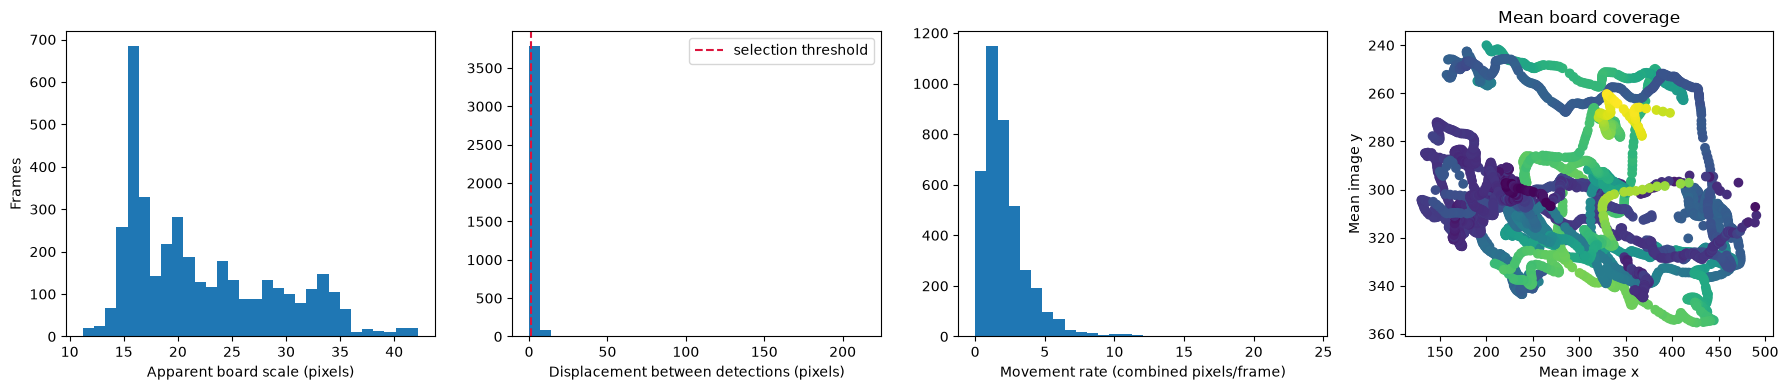

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].hist(detections.board_scale, bins=30)
axes[0].set(xlabel='Apparent board scale (pixels)', ylabel='Frames')
axes[1].hist(detections.movement.dropna(), bins=30)
axes[1].axvline(MAX_MOVEMENT, color='crimson', linestyle='--', label='selection threshold')
axes[1].set(xlabel='Displacement between detections (pixels)')
axes[1].legend()
axes[2].hist(detections.movement_per_frame.dropna(), bins=30)
axes[2].set(xlabel='Movement rate (combined pixels/frame)')
axes[3].scatter(detections.center_x, detections.center_y, c=detections.board_scale)
axes[3].invert_yaxis()
axes[3].set(xlabel='Mean image x', ylabel='Mean image y', title='Mean board coverage')
plt.tight_layout()


## 3. Split validation blocks, then select calibration frames

The validation frames must be excluded **before** frame selection and calibration. Here, complete source-video time blocks are held out so nearly identical neighboring frames do not leak into both sets. The split is based on `frame_left`, so it stays consistent when `FRAME_STEP` changes. Tune the block duration to the speed of checkerboard motion. The remaining pool is filtered for stable, clear detections, then sampled for diverse image positions and apparent distances.

Selected 40 calibration pairs; reserved 23 quality-matched validation pairs


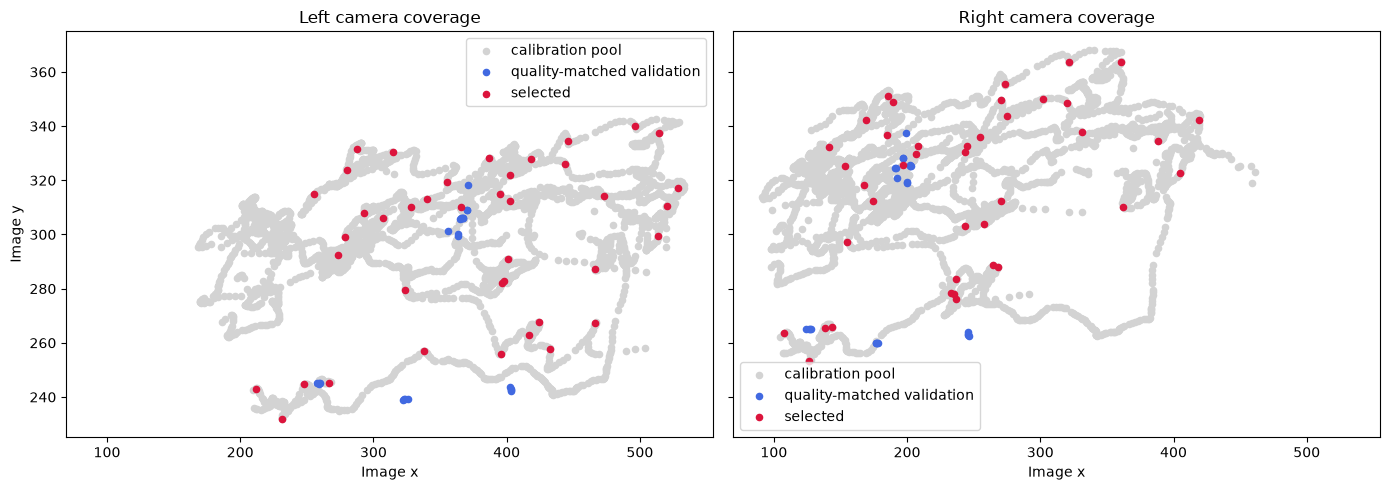

In [4]:
if detections.empty:
    raise RuntimeError('No paired checkerboards were detected; check paths, synchronization, and board size.')
if VALIDATION_EVERY_NTH_BLOCK < 2:
    raise ValueError('VALIDATION_EVERY_NTH_BLOCK must be at least 2.')

ordered = detections.sort_values('frame_left').reset_index(drop=True).copy()
ordered['temporal_block'] = ordered.frame_left // VALIDATION_BLOCK_SIZE_FRAMES
validation_mask = ordered.temporal_block.mod(VALIDATION_EVERY_NTH_BLOCK).eq(
    VALIDATION_EVERY_NTH_BLOCK - 1
)
calibration_pool = ordered.loc[~validation_mask].copy()
held_out = ordered.loc[validation_mask].copy()
if held_out.empty:
    raise RuntimeError('No validation block was created; reduce VALIDATION_BLOCK_SIZE_FRAMES.')
validation = held_out[
    (held_out.board_scale >= MIN_BOARD_SCALE)
    & (held_out.border_clearance >= MIN_BORDER_CLEARANCE)
    & (held_out.movement.fillna(np.inf) <= MAX_MOVEMENT)
].copy()
if validation.empty:
    raise RuntimeError('No held-out detections passed the calibration-quality thresholds.')

selected = select_calibration_pairs(
    calibration_pool, number=N_CALIBRATION_PAIRS, min_board_scale=MIN_BOARD_SCALE,
    min_border_clearance=MIN_BORDER_CLEARANCE, max_movement=MAX_MOVEMENT,
)
print(
    f'Selected {len(selected)} calibration pairs; '
    f'reserved {len(validation)} quality-matched validation pairs'
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, side in zip(axes, ['left', 'right']):
    xcol, ycol = f'center_{side}_x', f'center_{side}_y'
    calibration_pool.plot.scatter(
        x=xcol, y=ycol, color='lightgray', label='calibration pool', ax=ax
    )
    validation.plot.scatter(
        x=xcol, y=ycol, color='royalblue', label='quality-matched validation', ax=ax
    )
    selected.plot.scatter(
        x=xcol, y=ycol, color='crimson', label='selected', ax=ax
    )
    ax.invert_yaxis()
    ax.set(title=f'{side.title()} camera coverage', xlabel='Image x', ylabel='Image y')
plt.tight_layout()


## 4. Calibrate

The translation vector and subsequent reconstructed coordinates use the same unit as `SQUARE_SIZE`.

In [5]:
cap = cv2.VideoCapture(str(LEFT_VIDEO))
IMAGE_SIZE = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
cap.release()
calibration = calibrate_stereo(
    selected, corner_pairs, CHECKERBOARD_SIZE, SQUARE_SIZE, IMAGE_SIZE
)
print('Left RMS reprojection error:', calibration['rms_left'])
print('Right RMS reprojection error:', calibration['rms_right'])
print('Stereo RMS error:', calibration['rms_stereo'])
print('Estimated baseline:', np.linalg.norm(calibration['translation']), 'mm')
save_calibration(CALIBRATION_FILE, calibration)
print('Saved:', CALIBRATION_FILE)

# Reload the portable artifact; all validation below uses exactly what was saved.
with np.load(CALIBRATION_FILE) as archive:
    calibration = {name: archive[name] for name in archive.files}
print(f'Reloaded {len(calibration)} calibration fields from disk')

Left RMS reprojection error: 0.6827215661305183
Right RMS reprojection error: 0.730712207528183
Stereo RMS error: 0.7589485423389721
Estimated baseline: 100.90501087960229 mm
Saved: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2019southwater_stereo_calibration.npz
Reloaded 21 calibration fields from disk


## 5. Validate on quality-matched reserved checkerboards

This is a small guard against accepting a calibration that fits its selected frames but fails elsewhere in the recording. The test uses only reserved frames that pass the **same board-scale, border-clearance, and movement thresholds** as the calibration candidates. Moving, distant, and otherwise out-of-scope detections are retained in `held_out` for optional diagnostics, but they do not determine whether the calibration passes.

In [6]:
held_out['median_vertical_error'] = [
    np.median(vertical_disparity(*corner_pairs[int(frame)], calibration))
    for frame in held_out.frame_left
]
held_out['max_vertical_error'] = [
    np.max(vertical_disparity(*corner_pairs[int(frame)], calibration))
    for frame in held_out.frame_left
]
validation = held_out.loc[validation.index].copy()
validation_errors = np.concatenate([
    vertical_disparity(*corner_pairs[int(frame)], calibration)
    for frame in validation.frame_left
])
print(f'Quality-matched validation frames: {len(validation)}')
print(f'Checkerboard corners: {len(validation_errors)}')
print(f'Median vertical disparity: {np.median(validation_errors):.3f} px')
print(f'95th percentile: {np.percentile(validation_errors, 95):.3f} px')
print(f'Maximum: {np.max(validation_errors):.3f} px')
validation[['median_vertical_error', 'max_vertical_error']].describe()

Quality-matched validation frames: 23
Checkerboard corners: 1104
Median vertical disparity: 0.497 px
95th percentile: 1.631 px
Maximum: 6.225 px


,median_vertical_error,max_vertical_error
count,23.000000,23.000000
mean,0.522033,2.354817
std,0.196408,1.581796
min,0.165298,0.655823
25%,0.399139,1.414200
50%,0.502434,1.706116
75%,0.619392,2.506714
max,1.049225,6.225128


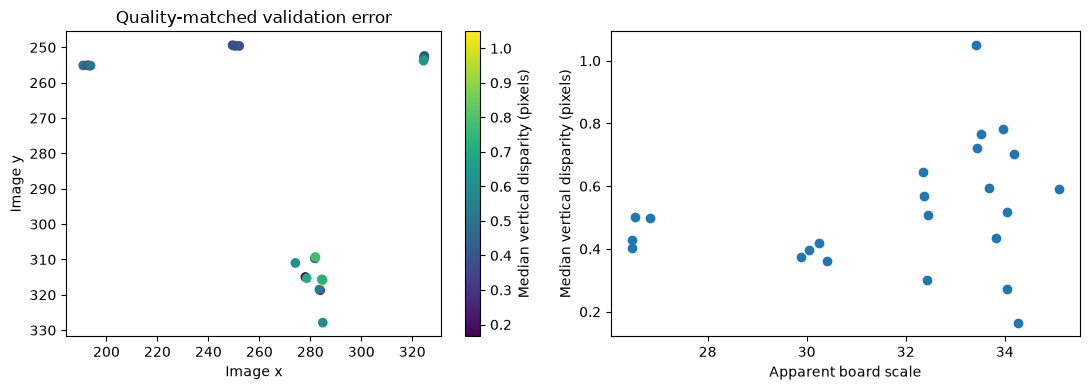

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sc = axes[0].scatter(validation.center_x, validation.center_y, c=validation.median_vertical_error)
axes[0].invert_yaxis(); axes[0].set(title='Quality-matched validation error', xlabel='Image x', ylabel='Image y')
fig.colorbar(sc, ax=axes[0], label='Median vertical disparity (pixels)')
axes[1].scatter(validation.board_scale, validation.median_vertical_error)
axes[1].set(xlabel='Apparent board scale', ylabel='Median vertical disparity (pixels)')
plt.tight_layout()

## 6. Visual epipolar-line check

Inspect a difficult quality-matched validation frame rather than a training example. This cell chooses the reserved frame with the largest median vertical checkerboard error. Corresponding checkerboard corners should lie on the same horizontal guides in both rectified views; inspect non-checkerboard scene features too.

Text(0.5, 1.0, 'Worst held-out frame 1260: median vertical error 1.05 px')

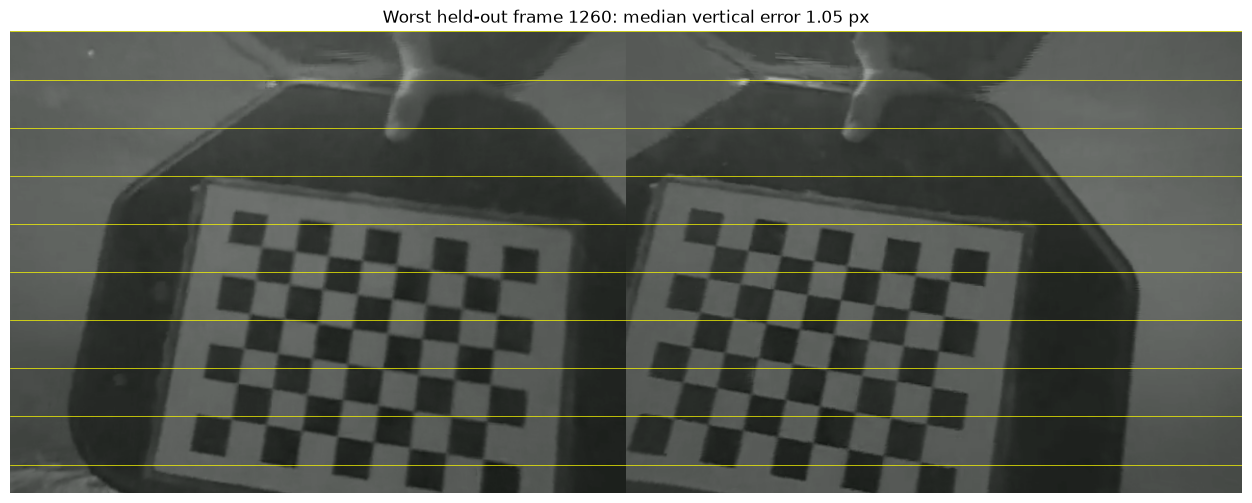

In [8]:
example = validation.loc[validation.median_vertical_error.idxmax()]
frame = int(example.frame_left)
right_frame = int(example.frame_right)
cap_l, cap_r = cv2.VideoCapture(str(LEFT_VIDEO)), cv2.VideoCapture(str(RIGHT_VIDEO))
cap_l.set(cv2.CAP_PROP_POS_FRAMES, frame); cap_r.set(cv2.CAP_PROP_POS_FRAMES, right_frame)
ok_l, image_l = cap_l.read(); ok_r, image_r = cap_r.read(); cap_l.release(); cap_r.release()
if not (ok_l and ok_r):
    raise RuntimeError(f'Could not read held-out frame pair {frame}, {right_frame}')
rect_l, rect_r = rectify_pair(image_l, image_r, calibration)
combined = np.hstack([cv2.cvtColor(rect_l, cv2.COLOR_BGR2RGB), cv2.cvtColor(rect_r, cv2.COLOR_BGR2RGB)])
plt.figure(figsize=(16, 6)); plt.imshow(combined)
for y in range(0, combined.shape[0], 50): plt.axhline(y, color='yellow', linewidth=0.5)
plt.axis('off')
plt.title(
    f'Worst held-out frame {frame}: median vertical error '
    f'{example.median_vertical_error:.2f} px'
)